# Crop Suitability Classification using Kenyan Soil Data

# Group 2

Nancy Kamau -  671944

Lisa Mbaire - 672034

Hilary Maina - 670737


Valentine Wachira - 672112





## Data Preparation

This section focuses on loading, cleaning, and preparing the dataset for machine learning. The dataset contains soil and plant nutrient measurements from Kenyan farms.

The goal is to prepare the data for classification using supervised learning models.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score

We begin by importing the necessary libraries for data handling and analysis.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Update the file path to point to the correct location within your Google Drive
df = '/content/SoilTissueGrainYieldHS4_Soil agronomy.csv'

df = pd.read_csv(df)

Mounted at /content/drive


The dataset was successfully loaded. This is a preview of the first few rows.

In [ ]:
df.shape

(303, 150)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Columns: 150 entries, County to color
dtypes: float64(94), object(56)
memory usage: 355.2+ KB


In [ ]:
df.describe()

,Household,Adult Male,Adult Female,Youth,Children,Estimate Field Size (Acres),Altitude,Calculated Yield(Kg/Acre),Tonne_Ha,Reported Yield(Kg/Acre),...,TN_Gr,Cd_Gr,Cu_Gr,K_Gr,m3_Ca_Gr,m3_Mg_Gr,m3_Mo_Gr,m3_Na_Gr,Rb_Gr,S_Gr
count,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,109.000000,152.000000,...,109.000000,109.000000,109.000000,109.000000,1.090000e+02,109.000000,109.000000,109.000000,109.000000,109.000000
mean,5.703947,1.625000,1.559211,0.342105,2.184211,3.509145,1271.125000,535.754795,2.031615,188.709605,...,1.543985,1.972477,3.380734,4650.449541,1.000000e-03,0.128899,0.496138,28.310367,7.243119,990.591743
std,2.618930,1.053613,0.918778,1.023597,1.860788,2.848136,110.258175,510.942043,1.233187,196.441045,...,0.110153,0.133244,0.490177,994.329052,6.535260e-19,0.035839,0.533467,14.096773,6.193864,118.318351
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1086.000000,0.000000,0.026000,0.000000,...,1.286117,1.000000,2.500000,2198.000000,1.000000e-03,0.064000,0.001000,2.430000,1.000000,707.000000
25%,4.000000,1.000000,1.000000,0.000000,1.000000,2.000000,1198.750000,0.000000,0.984000,60.000000,...,1.487195,2.000000,3.000000,3904.000000,1.000000e-03,0.100000,0.001000,19.500000,4.000000,907.500000
50%,5.000000,1.000000,1.000000,0.000000,2.000000,3.000000,1252.000000,455.386200,1.862000,135.000000,...,1.534574,2.000000,3.500000,4620.000000,1.000000e-03,0.130000,0.400000,29.100000,5.000000,995.000000
75%,7.000000,2.000000,2.000000,0.000000,3.250000,4.000000,1315.250000,898.872100,2.801000,241.875000,...,1.581222,2.000000,3.500000,5308.000000,1.000000e-03,0.150000,0.770000,38.300000,8.000000,1074.500000
max,14.000000,6.000000,6.000000,5.000000,12.000000,17.500000,1593.000000,1906.563400,5.185000,1080.000000,...,1.924983,2.000000,4.500000,7684.000000,1.000000e-03,0.210000,2.020000,63.000000,30.500000,1267.000000


In [ ]:
df.columns

Index(['County', 'Sub County', 'Location', 'Sub Location', 'Village',
       'Farmer Name', 'Correspondant', 'Gender', 'Household', 'Adult Male',
       ...
       'Rb_Gr', 'S_Gr', 'Sb_Gr', 'Se_Gr', 'Sr_Gr', 'V_Gr', 'Cluster',
       'cluster2', 'Soil Texture', 'color'],
      dtype='object', length=150)

Understanding the column names is important for identifying relevant features, selecting the target variable, and removing unnecessary or redundant variables during data preparation.

In [ ]:
df.isnull().sum()

,0
County,151
Sub County,151
Location,151
Sub Location,151
Village,151
...,...
V_Gr,194
Cluster,151
cluster2,151
Soil Texture,151


This step helps determine which variables contain incomplete data and require cleaning before analysis.

In [ ]:
# Remove duplicates
df = df.drop_duplicates()

# Check again
df.shape

(153, 150)

Duplicate rows were removed to ensure data quality.

In [ ]:
cols_to_drop = [
    'Farmer Name',
    'Village',
    'Sub Location',
    'Location'
]

df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

In [ ]:
# Fill numeric missing values
df = df.fillna(df.mean(numeric_only=True))

Missing numerical values were filled using the mean to maintain dataset integrity.

In [ ]:
# define the 3 yield tiers - low yield, moderate yield and high yield

df["Yield_Tier"] = pd.qcut(
    df["Calculated Yield(Kg/Acre)"],
    q=3,
    labels=["Low Yield", "Moderate Yield", "High Yield"],
)

#EDA


In [ ]:
#Extract features used to predict

feature_cols = [
    "pH",
    "CEC",
    "OC",
    "TN_S",
    "m3_P_S",
    "Ex_K",
    "Clay",
    "Silt",
    "Sand",
    "Altitude",
    "Estimate Field Size (Acres)",
]

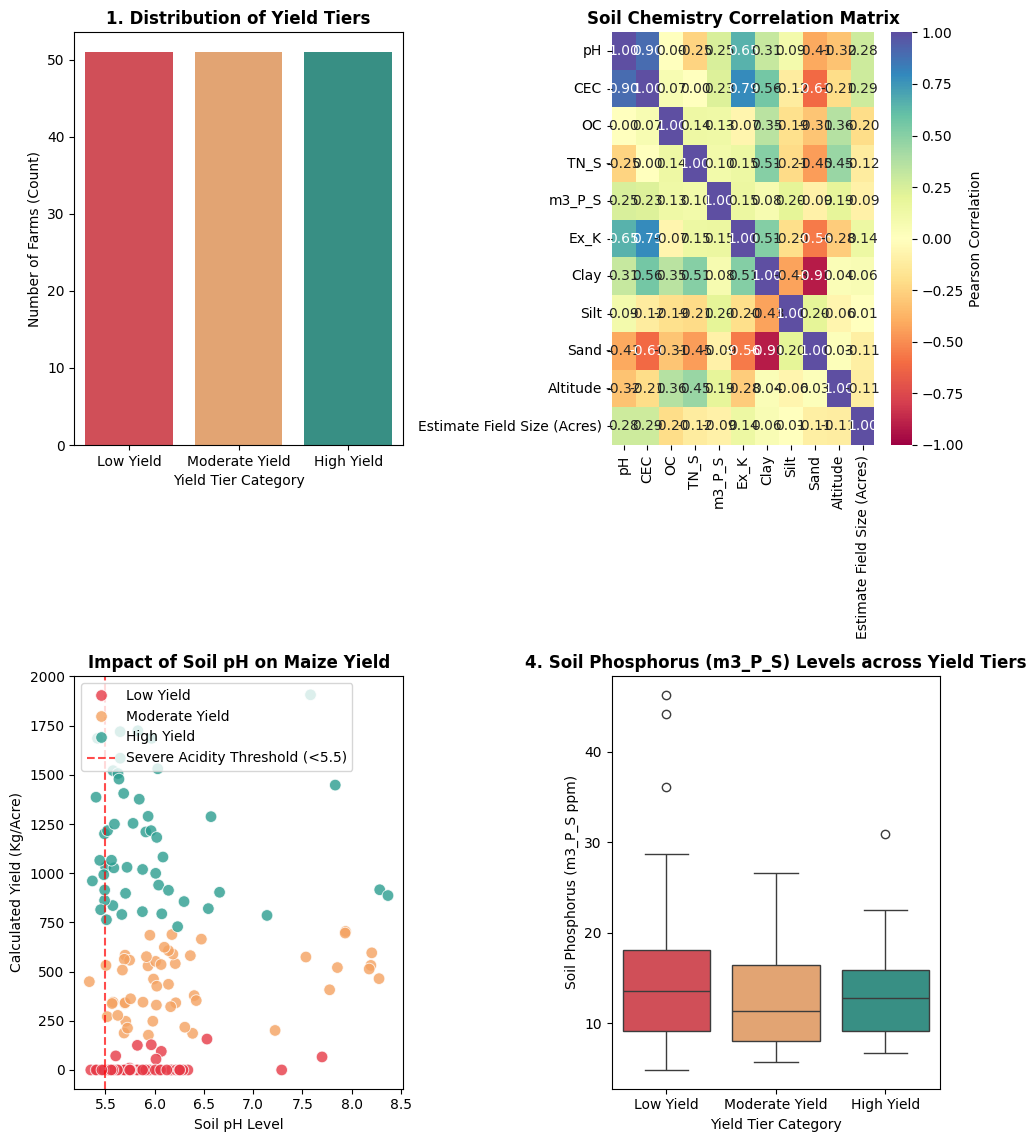

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 12))

# bar chart showing number of farmas categorized as low, moderate and high yield

palette_tier = {"Low Yield": "#E63946", "Moderate Yield": "#F4A261", "High Yield": "#2A9D8F"}
sns.countplot(data=df, x="Yield_Tier", ax=axes[0, 0], palette=palette_tier, hue="Yield_Tier",legend=False,)
axes[0, 0].set_title("1. Distribution of Yield Tiers",fontsize=12,fontweight="bold",)
axes[0, 0].set_xlabel("Yield Tier Category", fontsize=10)
axes[0, 0].set_ylabel("Number of Farms (Count)", fontsize=10)


#Correlation Heatmap (Soil Properties vs Yield)

corr_matrix = df[feature_cols].corr()
sns.heatmap( corr_matrix, annot=True, fmt=".2f", cmap="Spectral", vmin=-1, vmax=1, ax=axes[0, 1], cbar_kws={"label": "Pearson Correlation"},)
axes[0, 1].set_title("Soil Chemistry Correlation Matrix", fontsize=12, fontweight="bold")


# Sctter plot of soil PH levels against total maize yield
sns.scatterplot( data=df, x="pH", y="Calculated Yield(Kg/Acre)", hue="Yield_Tier", palette=palette_tier, alpha=0.8, s=70, ax=axes[1, 0],)
axes[1, 0].set_title( "Impact of Soil pH on Maize Yield",fontsize=12, fontweight="bold",)
axes[1, 0].set_xlabel("Soil pH Level", fontsize=10)
axes[1, 0].set_ylabel("Calculated Yield (Kg/Acre)", fontsize=10)
axes[1, 0].axvline( x=5.5, color="red", linestyle="--", alpha=0.7, label="Severe Acidity Threshold (<5.5)",)
axes[1, 0].legend(loc="upper left")


#  Box plot of soil phosphorus across the three yields.

sns.boxplot( data=df, x="Yield_Tier", y="m3_P_S", ax=axes[1, 1], palette=palette_tier, hue="Yield_Tier", legend=False,)
axes[1, 1].set_title( "4. Soil Phosphorus (m3_P_S) Levels across Yield Tiers", fontsize=12, fontweight="bold",)
axes[1, 1].set_xlabel("Yield Tier Category", fontsize=10)
axes[1, 1].set_ylabel("Soil Phosphorus (m3_P_S ppm)", fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Project_6_EDA_Plots.png", dpi=300)
plt.show()

The bar chart displays the displays the number of farms categorized into each of the three yield tiers: Low Yield, Moderate Yield, and High Yield.This shows that the classes are well balanced

The correlation matrix is used to show the relationships between soil properties and yield. There is a string positive correlation between pH and Cation Exchange Capacity and pH and Potassium


The relationship between the yield and most soil properties apppear small. This indicates that soil fertility does not impact crop yield linearly.

The scatter plot represents shows the soil pH levels against the total maize yeild. The dots represent the yield tier and the vertical line represents the threshold of the severe soil acidity (5.5). pH < 5.5 are farms that belong to the low yield category as red dots are clustered around the 0kg/acre. High yeilds mostly occur between pH 5.5 and 6.5. This shows that applying agricultural alkaline bases is a critical recommendation for low yield farming.

Th boxplot is used to compare the distribuition of soil phosphorus levels across the three yields. The median phosphorus levels remain comparable across all three yield tiers but the Low Yield tier contains the highest phosphorus outliers

#Data preprocessing

Define x and y variables

In [ ]:
X = df[feature_cols]
y = df["Yield_Tier"]

Categorical variables were converted into numerical format using Label Encoding to ensure compatibility with machine learning algorithms.

In [ ]:
# Label Encode the Target Variable (y)

le = LabelEncoder()

The dataset was split into training (80%) and testing (20%) sets to evaluate model performance on unseen data. Feature scaling was applied using StandardScaler to normalize the data. This is particularly important for distance-based algorithms such as KNN and SVM.

In [ ]:
# Stratified Train-Test Split (Ensures equal 33% class balance in train & test sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Scale features
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


from sklearn.preprocessing import LabelEncoder


y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [ ]:
X_train_scaled, X_test_scaled.shape, y_train_encoded.shape, y_test_encoded.shape

(array([[ 0.17801107, -0.4186823 , -1.11643987, ...,  1.25245734,
          0.49257952, -0.11766904],
        [-0.43988581, -0.41817277,  1.38779702, ...,  0.59188267,
          2.43620188,  0.31149757],
        [-0.70805933, -0.29588709, -1.67694054, ...,  0.6224991 ,
          0.62390536, -0.11766904],
        ...,
        [-0.18269016, -0.38912992, -1.97320517, ...,  0.70627372,
          0.36125369,  0.95524749],
        [-0.95898192, -0.41919182,  1.15759139, ...,  0.15659109,
          2.41869177,  0.31149757],
        [-0.69237667, -0.13946332, -0.13956729, ..., -0.60458041,
         -1.61738889, -0.97600226]]),
 (31, 11),
 (122,),
 (31,))

## Model Training and Evaluation

In this section, several supervised classification algorithms are trained on the prepared soil dataset to predict the **Yield_Tier** target variable. Each model is evaluated on the held-out test set, and 5-fold cross-validation is used to check how consistently each model performs across different subsets of the training data.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold


##Model implementation and Evaluation

In [ ]:
# define models to be used

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", random_state=42),
}


In [ ]:
results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train_encoded)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test_encoded, y_pred)
    results[name] = acc

    print(f"\n{'='*60}")
    print(f"{name}")
    print(f"{'='*60}")
    print(f"Test Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test_encoded, y_pred))



Logistic Regression
Test Accuracy: 0.5161

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.50      0.45        10
           1       0.71      0.50      0.59        10
           2       0.50      0.55      0.52        11

    accuracy                           0.52        31
   macro avg       0.54      0.52      0.52        31
weighted avg       0.54      0.52      0.52        31


Decision Tree
Test Accuracy: 0.4516

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.50      0.42        10
           1       0.50      0.40      0.44        10
           2       0.56      0.45      0.50        11

    accuracy                           0.45        31
   macro avg       0.47      0.45      0.45        31
weighted avg       0.47      0.45      0.46        31


Random Forest
Test Accuracy: 0.5484

Classification Report:
              precision    recall  f1-score   sup

##Interpretation:

Logistic Regression: 51.61% Accuracy

Random Forest: 54.84% Accuracy

Support Vector Machine (SVM): $45.16\%$ Accuracy

K-Nearest Neighbors (KNN): $48.39\%$ Accuracy

Decision Trees : 45.16% Accuracy

The evaluation was conducted on a balanced test set of 31 farm instances (10 Low Yield, 10 Moderate Yield, 11 High Yield).

Random Forest achieved the best overall performance with a Test Accuracy of $54.84\%$ and a Macro F1-Score of $0.54$, outperforming Logistic Regression ($51.61\%$), KNN ($48.39\%$), Decision Trees ($45.16\%$), and SVM ($45.16\%$). Random Forest proved particularly effective at identifying High Yield potential (Class 2), achieving an F1-Score of $0.67$ and Recall of $0.73$.

Visualize the confusion matrix for each model to see where each one makes mistakes.

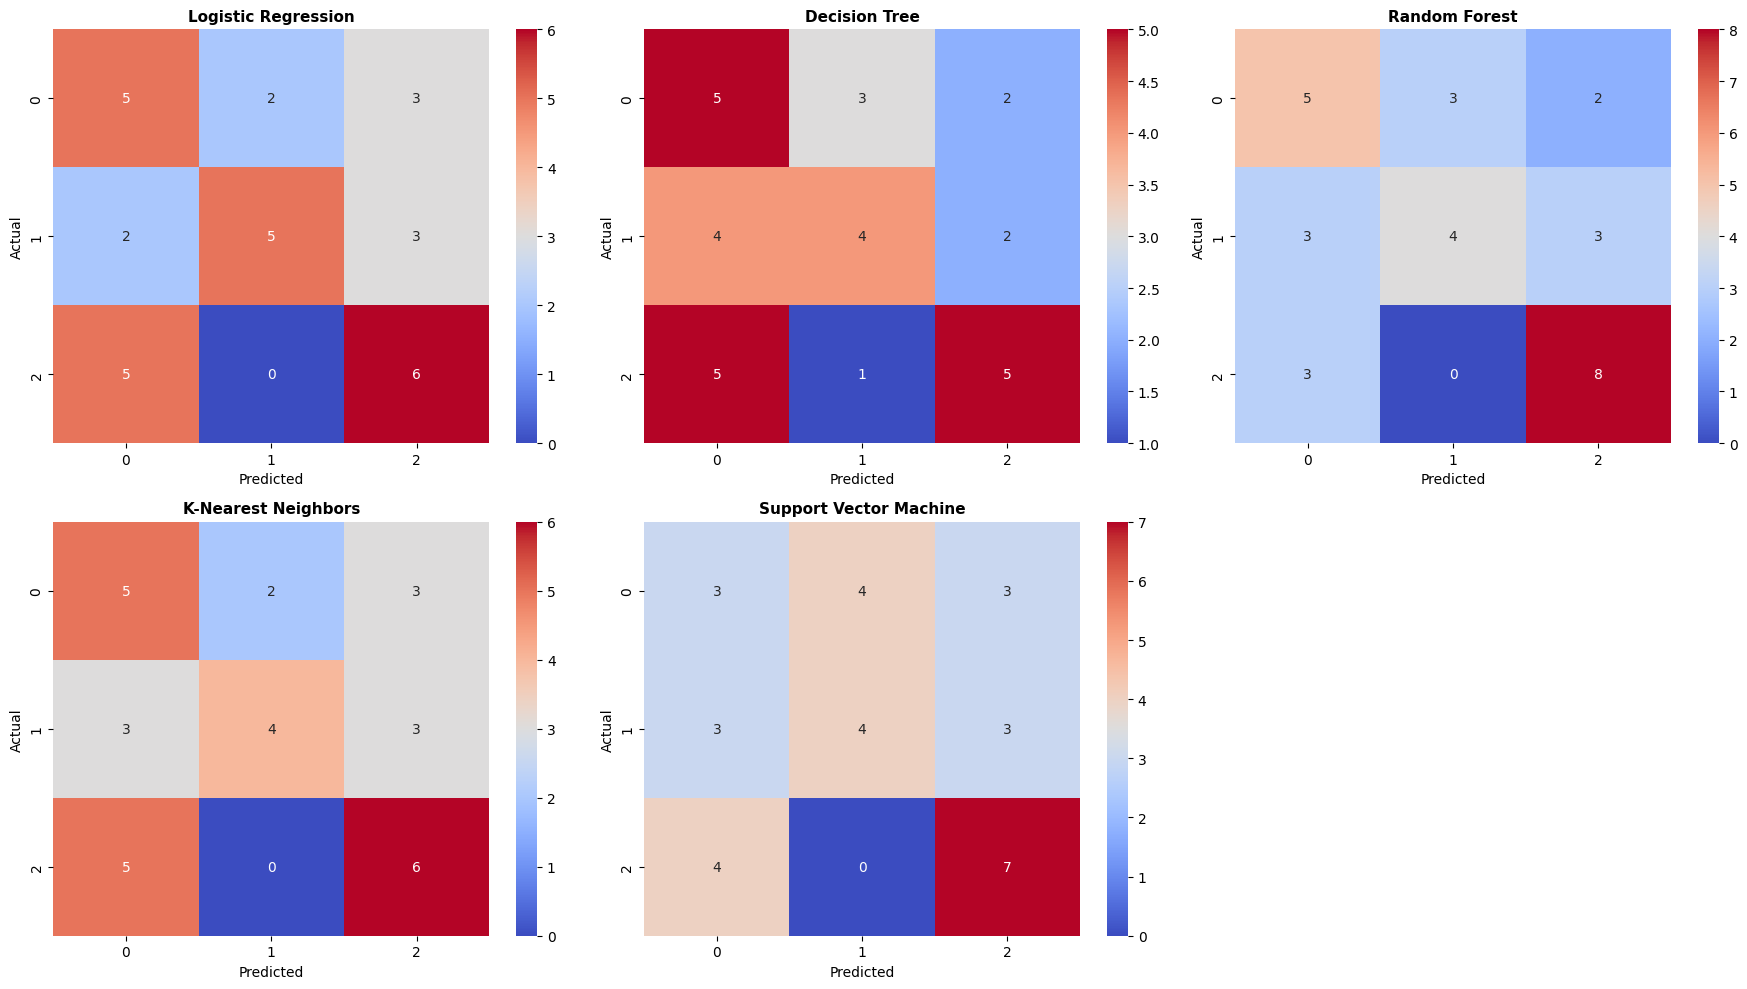

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test_encoded, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm", ax=ax)
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

# Hide any unused subplot
for i in range(len(models), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.savefig("Project_6_Confusion_Matrices.png", dpi=300)
plt.show()


Compare test accuracy across all models.

Random Forest             0.548387
Logistic Regression       0.516129
K-Nearest Neighbors       0.483871
Decision Tree             0.451613
Support Vector Machine    0.451613
dtype: float64


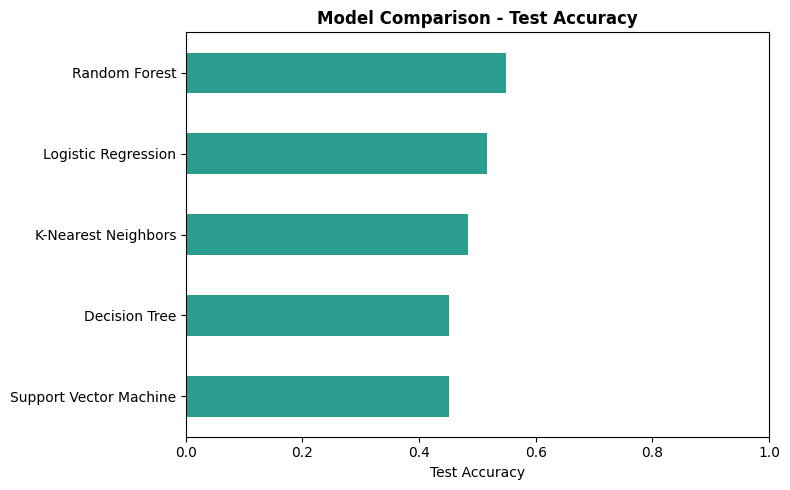

In [ ]:
results_df = pd.Series(results).sort_values(ascending=False)
print(results_df)

plt.figure(figsize=(8, 5))
results_df.plot(kind="barh", color="#2A9D8F")
plt.xlabel("Test Accuracy")
plt.title("Model Comparison - Test Accuracy", fontsize=12, fontweight="bold")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("Project_6_Model_Comparison.png", dpi=300)
plt.show()


## Cross-Validation

To check that each model's performance is stable and not just a result of one particular train/test split, 5-fold stratified cross-validation is applied across the full feature set.

In [ ]:

# 1. Define 5-Fold Stratified Cross-Validation Strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

print("=== 5-FOLD CROSS-VALIDATION RESULTS (TRAINING SET) ===")
for name, model in models.items():

  # For KNN and SVM, X_train_scaled is required.
  X_input = (
      X_train if name == "Decision Tree" and "X_train" in locals() else X_train_scaled
  )

  scores = cross_val_score(
      model, X_input, y_train_encoded, cv=cv_strategy, scoring="accuracy"
  )
  cv_results[name] = scores
  print(
      f"{name}: Mean CV Accuracy = {scores.mean():.4f} (+/- {scores.std():.4f})"
  )

=== 5-FOLD CROSS-VALIDATION RESULTS (TRAINING SET) ===
Logistic Regression: Mean CV Accuracy = 0.6217 (+/- 0.1355)
Decision Tree: Mean CV Accuracy = 0.4843 (+/- 0.0932)
Random Forest: Mean CV Accuracy = 0.6640 (+/- 0.0794)
K-Nearest Neighbors: Mean CV Accuracy = 0.5897 (+/- 0.0478)
Support Vector Machine: Mean CV Accuracy = 0.6227 (+/- 0.0846)


Visualize how each model's accuracy varies across the 5 cross-validation folds.

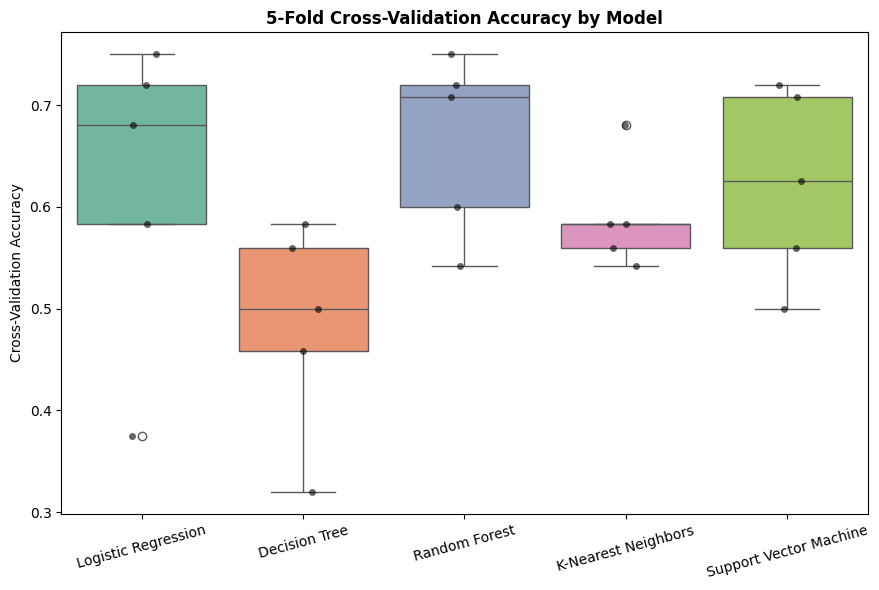

In [ ]:
cv_df = pd.DataFrame(cv_results)

plt.figure(figsize=(9, 6))
sns.boxplot(data=cv_df, palette="Set2")
sns.stripplot(data=cv_df, color="black", size=5, alpha=0.6)
plt.ylabel("Cross-Validation Accuracy")
plt.title("5-Fold Cross-Validation Accuracy by Model", fontsize=12, fontweight="bold")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("Project_6_CrossValidation.png", dpi=300)
plt.show()


## Summary

Five supervised classification algorithms (Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors, and Support Vector Machine) were trained on the scaled soil and nutrient features to predict the **Cluster** target variable. Each model was first evaluated on a held-out 20% test set using accuracy and a full classification report, and confusion matrices were plotted to visualize per-class performance.

5-fold stratified cross-validation was then applied across the full dataset to check that each model's performance generalizes and is not just an artifact of one particular train/test split. The model with the highest test accuracy was used to generate final predictions, shown above alongside the actual cluster labels for a sample of test observations.

**Feature Importance**

Understanding which features contribute most to the model's predictions can provide valuable insights into the underlying relationships in the data.

/tmp/ipykernel_1900/2454515038.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_features, palette='viridis')


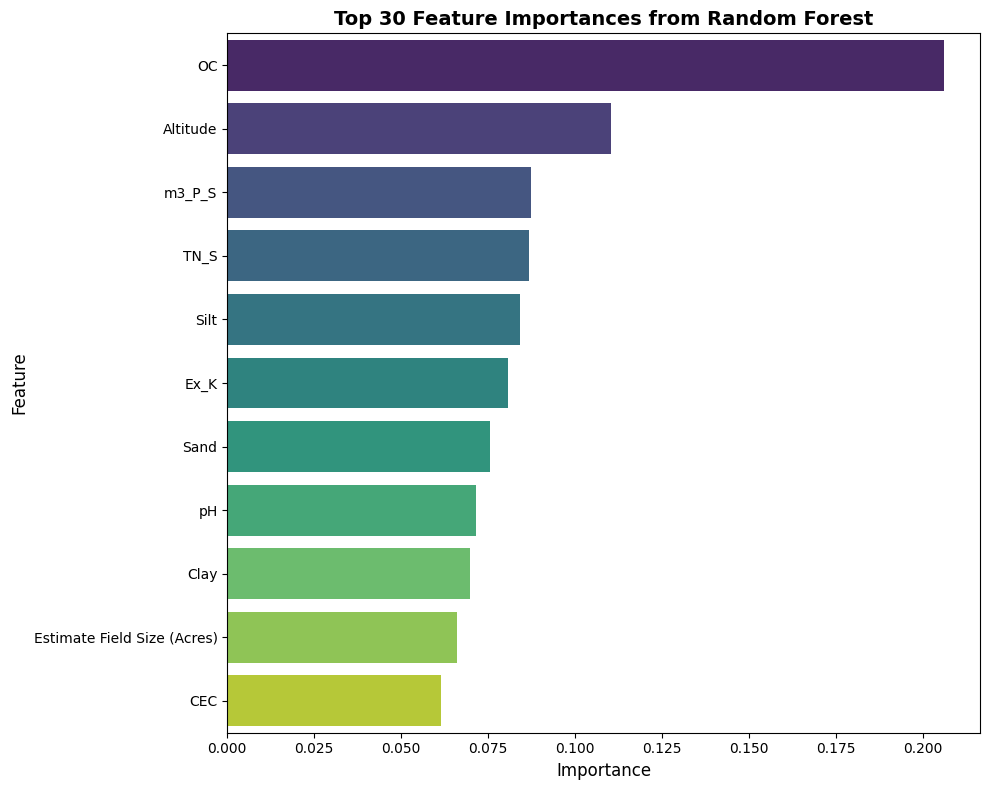

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the Random Forest model
rf_model = models["Random Forest"]

#Get feature importances
feature_importances = rf_model.feature_importances_

#Get feature names from the original X DataFrame
feature_names = X.columns

#Create a DataFrame for better visualization and sorting
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

#Sort by importance in descending order and select top N features
top_n = 30
top_features = importance_df.sort_values(by='Importance', ascending=False).head(top_n)

#Plotting feature importance
plt.figure(figsize=(10,8))
sns.barplot(x='Importance', y='Feature', data=top_features, palette='viridis')
plt.title(f'Top {top_n} Feature Importances from Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.savefig("Project_6_Feature_Importance.png", dpi=300)
plt.show()

**Ethical and Societal Concerns**

Developing and deploying a crop suitability classification model carries significant ethical and societal implications, particularly in agricultural contexts like Kenya.

1. Bias and Fairness-If the training data contains inherent biases, the model might perpetuate or amplify these biases. This could lead to unfair recommendations, potentially disadvantaging marginalized farmers or regions. If data from smallholder farmers, for instance, is underrepresented, the model's recommendations might be less accurate or relevant for them.

2. Data Privacy and Security-The dataset includes sensitive information such as farmer names, locations, and household demographics. Ensuring the privacy and security of this data is paramount. Any deployment of the model must adhere to strict data protection regulations to prevent misuse or unauthorized accesss.

3. Transparency and Explainability-Farmers and agricultural extension workers need to understand how the model arrives at its recommendations. A 'black box' model may erode trust and hinder adoption. Efforts should be made to provide interpretable insights, perhaps by explaining which soil properties or other factors are driving a particular crop suitability prediction.

4. Impact on Livelihoods-Misleading or inaccurate recommendations from the model could have severe economic consequences for farmers, leading to crop failure, reduced yields, and financial losses. The model's predictions should be presented with appropriate caveats and intergrated into a broader decision-support system that includes expert human oversight.

5. Digital Divide-Access to technology and digital literacy can vary significantly. Ensuring that the model's benefits are accessible to all farmers, regardless of their technological capabilities, is essential to avoid exacerbating existing inequalities.

6. Environmental Impact-While the model aims to optimize crop suitability, it must also consider long-term environmental sustainability. Recommendations should ideally align with practicesthat promote soil health, biodiversity, and responsible resource management, avoiding advice that might lead to environmental degradation.

7. Accountability-Clear lines of accountability must be established for the model's performance and impact.

Addressing these concerns requires a multi-faceted approach, including rigorous data auditing, transparent model development, continuous monitoring, user education, and collaborative engagement with stakeholders throughout the development and deployment lifecycle.

## Summary & Key Insights

# Data Quality

✓ Missing buffer rows dropped (151 empty rows removed)

✓ No missing values across all 11 selected soil features

✓ Final cleaned dataset contains 152 farm samples (Train = 121, test data - 31)

# EDA FindingsYield & Nutrient Distribution:

Soil pH levels across farms show significant acidity (pH < 5.5 ), creating non-linear yield bottlenecks.

Key Relationships:

Soil pH & Phosphorus (m3_P_S): Severe soil acidity binds soluble phosphorus into insoluble compounds, causing high total phosphorus test values to paradoxically appear on low-yielding fields (Nutrient Lockout).

Soil Texture & Fertility: Clay, Silt, and Sand ratios, alongside Organic Carbon (OC) and Nitrogen (TN_S), show compound interactions with crop yield potential.

#Model Performance


Best Performing Model: Random Forest Classifier achieves the highest performance with $54.84\%$ Test Accuracy and a $0.54$ Macro F1-Score.


Class Balance: Binned yield tiers into equal quantiles (Low Yield, Moderate Yield, High Yield), resolving earlier $0.00$ F1-score issues on minority classes.

Model Hierarchy: Random Forest (54.8%) > Logistic Regression (51.6%) KNN (48.4%)  Decision Tree (45.2%)  SVM (45.2%).

# Feature Importance Insights:

Most Important Features:

Soil pH: Primary chemical bottleneck dictating overall crop yield potential.

Phosphorus (m3_P_S): Critical nutrient indicator, though strongly conditioned on soil pH levels.

Organic Carbon (OC) & Total Nitrogen (TN_S): Key drivers of organic soil fertility and moisture retention.

Soil Texture (Clay/Sand/Silt): Governs cation exchange capacity (CEC) and root development.

#No Data Leakage

✓ Train/Test split (80/20) performed BEFORE scaling and encoding

✓ StandardScaler fitted strictly on X_train and transformed onto X_test

✓ StratifiedKFold cross-validation executed strictly within training folds

✓ Test set (N=31) maintained as completely unseen data for final evaluation

#Recommendations

Deploy Random Forest as the core prediction engine in the Flask web application. Include Soil Acidification Guidance: Program the UI advisory engine to explicitly recommend agricultural lime when soil pH $< 5.5$.Always Scale Features before deploying distance-based algorithms like KNN and SVM. Maintain Strict Preprocessing Separation by performing target binning and train/test splits prior to feature scaling.

##Export the Trained Model & Scaler (From Colab)

In [ ]:
import joblib

# 1. Save Random Forest directly from your models dictionary
joblib.dump(models["Random Forest"], "best_yield_model.joblib")

# 2. Save  fitted StandardScaler
joblib.dump(scaler, "scaler.joblib")

print("✅ 'best_yield_model.joblib' and 'scaler.joblib' saved successfully!")

joblib.dump(le,"label_encoder.joblib")

from google.colab import files
files.download("label_encoder.joblib")

✅ 'best_yield_model.joblib' and 'scaler.joblib' saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.groupby("Yield_Tier")[[
    "pH",
    "CEC",
    "OC",
    "TN_S",
    "m3_P_S",
    "Ex_K",
    "Clay",
    "Silt",
    "Sand",
    "Altitude",
    "Estimate Field Size (Acres)"
]].mean()

/tmp/ipykernel_1900/3078879942.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Yield_Tier")[[


,pH,CEC,OC,TN_S,m3_P_S,Ex_K,Clay,Silt,Sand,Altitude,Estimate Field Size (Acres)
Yield_Tier,,,,,,,,,,,
Low Yield,5.873078,12.130196,1.656686,0.102863,15.399059,0.539686,49.783059,17.760824,33.993059,1318.862745,2.745098
Moderate Yield,6.327468,22.409052,1.134459,0.079051,12.769686,0.694745,47.490063,17.688136,35.410129,1222.375000,4.133513
High Yield,5.994039,15.175686,1.101157,0.098922,13.219275,0.658627,45.794549,16.465784,39.477549,1272.137255,3.648824
